# ICT-15k — Recollement des macrocells : le quadtree de Hashlife comme espace étalé

## Question et hypothèses

Le quadtree de Hashlife définit-il un recouvrement de la grille Life dont le recollement est compatible avec les frontières des macrocells ? Et, si la clé ignore une frontière, un cycle concret peut-il exploiter cette incompatibilité et produire un témoin qui gagne contre l’agent ? Le recouvrement est imposé par les macrocells alignées sur `2^k`, donc par le substrat plutôt que par un choix de l’expérimentateur. La mémoïsation réutilise les occurrences d’une forme canonique; la frontière doit donc faire partie de la clé pour que le transport soit compatible. Le résultat antérieur `TRIVIAL` provenait d’une cochaîne pondérée qui ne construisait ni le nerf ni la condition de cocycle; le protocole présent construit un recouvrement induit par le substrat et cherche un cycle témoin concret.

La chaîne étudiée est : information → quotients / fibres → transports → compatibilité → obstruction.

## Objectifs et protocole

1. Poser le **recouvrement** d’une grille Life par des macrocells alignées sur `2^k`.
2. Définir les **fibres** (occurrences d’une même forme canonique), les **transports** (réutilisation mémoïsée d’une occurrence à l’autre) et la **condition de compatibilité** (la frontière compte dans la clé).
3. Vérifier empiriquement le recollement sain (marge 1) : zéro divergence et transports tous exacts.
4. Tester la **Loi I** : produire un cycle concret qui exploite un défaut de recollement si le détecteur prétend en trouver un, par un agent parieur et un bookmaker qui connaît la vérité terrain.
5. Mesurer la sensibilité au choix du recouvrement avec la variante -b (marges 0, 1 et 2).

## Protocole pédagogique

Les expériences comparent un recollement sain et un recollement cassé. Le témoin doit payer : un signal de défaut sans cycle exploitable ne suffit pas. La variante -b détermine si le résultat dépend du choix de marge. Le notebook conduit ainsi du recouvrement imposé par le substrat à une vérification empirique de compatibilité et à une tentative falsifiable de détecter son défaut.

**Prérequis.** [ICT-Life-SubstratCertifie-Python](../ICT-Life-SubstratCertifie-Python.ipynb) (certificat B3/S23 et pont Lean `hashlife_correct`), [ICT-31-ContrasteTroisSubstrats-Python](../ICT-31-ContrasteTroisSubstrats-Python.ipynb), bases C#. Dépendances externes : ScottPlot.

**Durée estimée.** Environ 1 h.

**Plan.** §1 Le recouvrement imposé ; §2 le cadre macrocell ; §3 le recollement sain ; §4 le recollement cassé ; §5 la Loi I et le bookmaker ; §6 la sensibilité au recouvrement et au substrat ; exercices et synthèse.

> **Statut épistémique** — **Sans verdict à ce jour** : aucune ligne de la [matrice de dissociations](../../../../docs/ict/dissociations-matrix.md) ne concerne ce notebook ; son statut épistémique sera porté par la matrice le cas échéant.

> **Acquis et parenté** : chantier 3 — reprend là où [ICT-15d-CechObstruction-Python](ICT-15d-CechObstruction-Python.ipynb) avait rendu son verdict TRIVIAL, et rend observable la dette §2 de [#12206](https://github.com/jsboige/CoursIA/issues/12206) : le recouvrement imposé par le substrat (bords définis avant les sections).

## 1. Le recouvrement impose par le substrat

En topologie algebrique, un **recouvrement** d'un espace est une famille d'ouverts dont l'union recouvre tout ; les donnees definies sur chaque ouvert (les **sections**) doivent **se recoller** sur les intersections. Le strand 15b-15i pretendait detecter des obstructions a un tel recollement — mais sur un recouvrement que l'experimentateur choisissait lui-meme, et sans jamais ecrire la condition de cocycle. La lecon du verdict `TRIVIAL` (#7744) : *l'experience avait mesure la mauvaise chose*.

Hashlife nous offre le contre-exemple canonique. L'algorithme de Gosper decoupe la grille en **quadtree** : chaque noeud de niveau k couvre un carre de `2^k` cases. Ce decoupage n'est pas un choix de l'experimentateur — il est **impose par le substrat** :

- **Ouverts** : les macrocells de taille `2^k` alignees sur la grille (ici `k = 2`, des macrocells 4×4 sur une grille 64×64). *Les bords sont definis avant les sections* : la dette du §2 de #12206 est payee par construction, pas escamotee.
- **Sections** : le contenu booleen d'une macrocell.
- **Fibre** : pour une forme canonique donnee (la cle de memoisation), l'ensemble des occurrences — toutes les positions et tous les instants ou cette section reapparait.
- **Transport** : quand la memo reutilise une valeur calculee ailleurs, la valeur *voyage* le long de la fibre.
- **Condition de compatibilite** : deux macrocells voisines se chevauchent sur une bande frontiere ; la regle de Life (voisinage de Moore, rayon 1) fait que l'avenir d'une cellule de bord depend de cette bande. Une cle qui l'oublie recolle deux sections incompatibles.

Le pont Lean ([ICT-Life, §5](../ICT-Life-SubstratCertifie-Python.ipynb)) certifie le cas general : `hashlife_correct` dans `conway_lean/Conway/Life/HashlifeCorrectness.lean` prouve que l'evaluation Hashlife et la simulation naive produisent **le meme film**. Ce notebook rend cette compatibilite **mesurable sur instances** — puis la casse exprès, pour voir si le defaut se convertit en temoin exploitable.

In [1]:
using System;
using System.Globalization;
using System.Collections.Generic;
using System.Linq;

CultureInfo.CurrentCulture = CultureInfo.InvariantCulture;
CultureInfo.CurrentUICulture = CultureInfo.InvariantCulture;

// ---------- Moteur B3/S23 naif : la verite terrain ----------
// Convention de bord : l'EXTERIEUR de la grille est mort, mais les cellules
// du bord evoluent normalement (memes regles que les patchs du §2 -- sans
// cette coherence, les deux moteurs mesureraient deux dynamiques differentes).
int[,] voisins(bool[,] g)
{
    int h = g.GetLength(0), w = g.GetLength(1);
    var n = new int[h, w];
    for (int i = 1; i < h - 1; i++)
        for (int j = 1; j < w - 1; j++)
            for (int di = -1; di <= 1; di++)
                for (int dj = -1; dj <= 1; dj++)
                    if ((di != 0 || dj != 0) && g[i + di, j + dj]) n[i, j]++;
    return n;
}

bool[,] pad(bool[,] g, int marge)
{
    int h = g.GetLength(0), w = g.GetLength(1);
    var p = new bool[h + 2 * marge, w + 2 * marge];
    for (int i = 0; i < h; i++)
        for (int j = 0; j < w; j++) p[i + marge, j + marge] = g[i, j];
    return p;
}

bool[,] extraire(bool[,] g, int ligne, int colonne, int hauteur, int largeur)
{
    var r = new bool[hauteur, largeur];
    for (int i = 0; i < hauteur; i++)
        for (int j = 0; j < largeur; j++) r[i, j] = g[ligne + i, colonne + j];
    return r;
}

bool egales(bool[,] a, bool[,] b)
{
    if (a.GetLength(0) != b.GetLength(0) || a.GetLength(1) != b.GetLength(1)) return false;
    for (int i = 0; i < a.GetLength(0); i++)
        for (int j = 0; j < a.GetLength(1); j++)
            if (a[i, j] != b[i, j]) return false;
    return true;
}

bool[,] pas_suivant(bool[,] g)
{
    int h = g.GetLength(0), w = g.GetLength(1);
    var gp = pad(g, 1);
    var n = voisins(gp);
    var resultat = new bool[h, w];
    for (int i = 0; i < h; i++)
        for (int j = 0; j < w; j++)
            resultat[i, j] = n[i + 1, j + 1] == 3 || (g[i, j] && n[i + 1, j + 1] == 2);
    return resultat;
}

int periode(bool[,] motif, int tmax = 12, int T = 40)
{
    int ph = motif.GetLength(0), pw = motif.GetLength(1);
    int o = (T - Math.Max(ph, pw)) / 2;
    var g0 = new bool[T, T];
    for (int i = 0; i < ph; i++)
        for (int j = 0; j < pw; j++) g0[o + i, o + j] = motif[i, j];
    var g = (bool[,])g0.Clone();
    for (int t = 1; t <= tmax; t++)
    {
        g = pas_suivant(g);
        if (egales(g, g0)) return t;
    }
    return -1;
}

int pas_diagonal(bool[,] motif, int T = 40, int tmax = 8)
{
    int ph = motif.GetLength(0), pw = motif.GetLength(1);
    int o = (T - Math.Max(ph, pw)) / 2;
    var g = new bool[T, T];
    for (int i = 0; i < ph; i++)
        for (int j = 0; j < pw; j++) g[o + i, o + j] = motif[i, j];
    for (int t = 1; t <= tmax; t++)
    {
        g = pas_suivant(g);
        if (egales(extraire(g, o + 1, o + 1, ph, pw), motif)) return t;
    }
    return -1;
}

var blinker = new bool[,] { { true, true, true } };
var glider = new bool[,] { { false, true, false }, { false, false, true }, { true, true, true } };
var bloc = new bool[,] { { true, true }, { true, true } };
Console.WriteLine("Calibration du moteur B3/S23 (constantes canoniques) :");
Console.WriteLine($"  blinker : periode            = {periode(blinker)}      (attendu 2)");
Console.WriteLine($"  bloc 2x2: periode            = {periode(bloc)}      (attendu 1)");
Console.WriteLine($"  glider  : pas / case diag.   = {pas_diagonal(glider)}      (attendu 4 -> c/4)");

Calibration du moteur B3/S23 (constantes canoniques) :


  blinker : periode            = 2      (attendu 2)


  bloc 2x2: periode            = 1      (attendu 1)


  glider  : pas / case diag.   = 4      (attendu 4 -> c/4)


### Lecture — le moteur herite du certificat

`blinker` p=2, `bloc` p=1, `glider` 4 pas par case diagonale (vitesse c/4) : le moteur reproduit les constantes canoniques du substrat certifie [ICT-Life-SubstratCertifie-Python](../ICT-Life-SubstratCertifie-Python.ipynb), lui-meme adosse au theoreme `hashlife_correct` prouve dans `conway_lean` (ICT-Life §5). Toute divergence mesuree dans la suite sera donc attributable au **recollement**, pas au moteur.

## 2. Le cadre macrocell : patch, cle canonique, memo

Le vocabulaire du §1 devient trois fonctions :

- le **patch** d'une macrocell = son interieur **plus une marge** de largeur `marge` prise dans la grille reelle (bord mort au-dela de la grille) ;
- la **cle canonique** = les octets du patch — deux occurrences de la meme section (marge comprise) produisent la meme cle : c'est le quotient ;
- la **memo** associe cle → valeur (l'interieur au pas suivant). Un **transport** = une lecture dans la memo ; la **compatibilite** exige que la valeur transportee coincide avec ce que le contexte reel de l'occurrence commandait.

La subtilite pedagogique tient en une cellule : *la meme section interieure a deux valeurs differentes selon sa frontiere*. Le corpus ci-dessous construit exactement cette situation — deux macrocells d'interieur identique (un bloc 2×2 colle au bord droit), dont une seule porte une cellule vivante juste au-dela de sa frontiere.

In [2]:
bool[,] centre_m(bool[,] res, int m)
{
    int c0 = (res.GetLength(0) - m) / 2;
    return extraire(res, c0, c0, m, m);
}

bool[,] pas_patch_centre(bool[,] patch)
{
    int h = patch.GetLength(0), w = patch.GetLength(1);
    var n = voisins(patch);
    var sortie = new bool[h - 2, w - 2];
    for (int i = 1; i < h - 1; i++)
        for (int j = 1; j < w - 1; j++)
            sortie[i - 1, j - 1] = n[i, j] == 3 || (patch[i, j] && n[i, j] == 2);
    return sortie;
}

bool[,] valeur_locale(bool[,] patch, int m) => centre_m(pas_patch_centre(patch), m);
bool[,] valeur_isolee(bool[,] inter, int m) => centre_m(pas_patch_centre(pad(inter, 1)), m);

bool[,] corpus_frontiere()
{
    var grille = new bool[64, 64];
    // macrocell A (rows 8-11, cols 12-15) : bloc au bord droit
    for (int i = 8; i < 10; i++) for (int j = 14; j < 16; j++) grille[i, j] = true;
    // macrocell B (rows 8-11, cols 44-47) : bloc identique
    for (int i = 8; i < 10; i++) for (int j = 46; j < 48; j++) grille[i, j] = true;
    // la cellule temoin, JUSTE au-dela de la frontiere de B
    grille[8, 48] = true;
    // deux gliders isoles pour habiller la grille
    for (int i = 0; i < 3; i++)
        for (int j = 0; j < 3; j++)
        {
            grille[40 + i, 8 + j] = glider[i, j];
            grille[40 + i, 40 + j] = glider[i, j];
        }
    return grille;
}

void afficher_grille(bool[,] grille)
{
    int h = grille.GetLength(0), w = grille.GetLength(1);
    for (int i = 0; i < h; i++)
    {
        Console.Write(i == 0 ? "[[" : " [");
        for (int j = 0; j < w; j++)
        {
            if (j > 0) Console.Write(" ");
            Console.Write(grille[i, j] ? "1" : "0");
        }
        Console.WriteLine(i == h - 1 ? "]]" : "]");
    }
}

var g = corpus_frontiere();
var gp = pad(g, 1);
var A = extraire(g, 8, 12, 4, 4);
var B = extraire(g, 8, 44, 4, 4);
// meme extraction que predire_recolle (marge 1)
var patchA = extraire(gp, 8, 12, 6, 6);
var patchB = extraire(gp, 8, 44, 6, 6);
Console.WriteLine($"Interieur A == interieur B : {egales(A, B)}  (meme section, meme fibre)");
Console.WriteLine($"Patch A == patch B         : {egales(patchA, patchB)}  (la frontiere distingue A de B)");
Console.WriteLine();
Console.WriteLine("Valeur LOCALE de A (pas de temoin dans la marge) :");
afficher_grille(valeur_locale(patchA, 4));
Console.WriteLine("Valeur LOCALE de B (frontiere reelle, le temoin compte) :");
afficher_grille(valeur_locale(patchB, 4));
Console.WriteLine("Valeur ISOLEE de B (la frontiere oubliee) :");
afficher_grille(valeur_isolee(B, 4));
Console.WriteLine($"Locale de A == isolee : {egales(valeur_locale(patchA, 4), valeur_isolee(A, 4))} | locale de B == isolee : {egales(valeur_locale(patchB, 4), valeur_isolee(B, 4))}");

Interieur A == interieur B : True  (meme section, meme fibre)


Patch A == patch B         : False  (la frontiere distingue A de B)


Valeur LOCALE de A (pas de temoin dans la marge) :


[[

0

0

... (68 outputs left out)

0

0

]]


Locale de A == isolee : True | locale de B == isolee : False


### Lecture — la fibre vue de pres

Les deux **interieurs** sont egaux : pour une cle qui ne regarde que l'interieur, A et B sont le **meme point du quotient** — une fibre a deux occurrences. Leurs **patchs** (marge 1) ne le sont pas : la cellule temoin vit juste au-dela de la frontiere de B. Consequence mesuree sur les trois valeurs ci-dessus :

- la valeur locale de A est **egale** a sa valeur isolee (bloc 2x2 stable, 4 cases) — la frontiere de A ne dit rien ;
- la valeur locale de B n'a **que la colonne gauche du bloc qui survit** : chaque cellule de la colonne de bord (adjacente au temoin) voit **4 voisins** vivants et meurt de surpopulation ; le temoin, lui, survit (vivant + 2 voisins).

*La section ne determine pas sa propre valeur — le recollement avec les voisins la determine.* C'est tout l'enjeu : une cle d'interieur seul transporterait la valeur de A (bloc stable) vers B, en ignorant que B ne recolle pas comme A — et l'experience du §4 montrera exactement cette collision.

## 3. Le recollement sain : la frontiere dans la cle

Protocole : a chaque pas, chaque macrocell predit son avenir via la memo. La **cle inclut la marge 1** — c'est la condition de compatibilite operationalisee. On mesure, contre la verite terrain (simulation naive de la grille entiere) :

- **transports** : nombre de lectures en memo (la valeur voyage le long des fibres) ;
- **transports faux** : lectures dont la valeur contredit le contexte reel de l'occurrence (instrument de collision) ;
- **divergences** : cellules ou la grille predite contredit la verite.

In [3]:
// Les clés codent exactement les cases du patch dans l'ordre des lignes.
string cle_patch(bool[,] patch)
{
    var caracteres = new char[patch.Length];
    int k = 0;
    for (int i = 0; i < patch.GetLength(0); i++)
        for (int j = 0; j < patch.GetLength(1); j++)
            caracteres[k++] = patch[i, j] ? '1' : '0';
    return new string(caracteres);
}

int population(bool[,] grille)
{
    int total = 0;
    foreach (bool caseVivante in grille) if (caseVivante) total++;
    return total;
}

int differences(bool[,] a, bool[,] b)
{
    int total = 0;
    for (int i = 0; i < a.GetLength(0); i++)
        for (int j = 0; j < a.GetLength(1); j++)
            if (a[i, j] != b[i, j]) total++;
    return total;
}

Dictionary<string, int> nouvelles_stats()
{
    return new Dictionary<string, int> {
        ["transports"] = 0, ["transports_faux"] = 0,
        ["divergences"] = 0, ["etapes_fausses"] = 0
    };
}

bool[,] predire_recolle(bool[,] grille, int m, int marge,
    Dictionary<string, bool[,]> memo, Dictionary<string, int> stats)
{
    int h = grille.GetLength(0), w = grille.GetLength(1);
    var pred = new bool[h, w];
    var grilleP = pad(grille, marge); // bord mort explicite : les patchs sont toujours pleins
    var grille1 = pad(grille, 1); // contexte reel, pour l'instrument de collision
    for (int i = 0; i < h; i += m)
        for (int j = 0; j < w; j += m)
        {
            var inter = extraire(grille, i, j, m, m);
            var patch = marge > 0 ? extraire(grilleP, i, j, m + 2 * marge, m + 2 * marge) : inter;
            string cle = cle_patch(patch);
            bool[,] valeur;
            if (memo.TryGetValue(cle, out valeur))
            {
                stats["transports"]++;
                var veritable = marge > 0
                    ? valeur_locale(patch, m)
                    : valeur_locale(extraire(grille1, i, j, m + 2, m + 2), m);
                if (!egales(valeur, veritable)) stats["transports_faux"]++;
            }
            else
            {
                valeur = marge > 0 ? valeur_locale(patch, m) : valeur_isolee(inter, m);
                memo[cle] = valeur;
            }
            for (int a = 0; a < m; a++)
                for (int b = 0; b < m; b++) pred[i + a, j + b] = valeur[a, b];
        }
    return pred;
}

(Dictionary<string, int> stats, int profit) experience(bool[,] initiale, int m, int marge, int T)
{
    // La grille avance sur la vérité et la mémoire persiste entre les étapes.
    var grille = (bool[,])initiale.Clone();
    var memo = new Dictionary<string, bool[,]>();
    var stats = nouvelles_stats();
    int profit = 0, premiere = 0;
    for (int t = 0; t < T; t++)
    {
        var verite = pas_suivant(grille);
        var pred = predire_recolle(grille, m, marge, memo, stats);
        int d = differences(pred, verite);
        if (d > 0)
        {
            stats["divergences"] += d;
            stats["etapes_fausses"]++;
            if (premiere == 0) premiere = t + 1;
            profit += Math.Abs(population(pred) - population(verite));
        }
        grille = verite;
    }
    stats["cles"] = memo.Count;
    stats["premiere_divergence"] = premiere;
    return (stats, profit);
}

string format_stats(Dictionary<string, int> s)
{
    string premiere = s["premiere_divergence"] == 0 ? "None" : s["premiere_divergence"].ToString(CultureInfo.InvariantCulture);
    return $"{{'transports': {s["transports"]}, 'transports_faux': {s["transports_faux"]}, 'divergences': {s["divergences"]}, 'etapes_fausses': {s["etapes_fausses"]}, 'cles': {s["cles"]}, 'premiere_divergence': {premiere}}}";
}

// Xorshift64* seedé : même protocole de tirage uniforme, générateur distinct de NumPy.
bool[,] soupe(int hauteur, int largeur, double densite, ulong seed)
{
    ulong etat = seed == 0 ? 0x9E3779B97F4A7C15UL : seed;
    var resultat = new bool[hauteur, largeur];
    for (int i = 0; i < hauteur; i++)
        for (int j = 0; j < largeur; j++)
        {
            etat ^= etat >> 12;
            etat ^= etat << 25;
            etat ^= etat >> 27;
            ulong tirage = unchecked(etat * 2685821657736338717UL);
            double uniforme = (tirage >> 11) * (1.0 / 9007199254740992.0);
            resultat[i, j] = uniforme < densite;
        }
    return resultat;
}

var soupe7 = soupe(64, 64, 0.35, 7);
var sainCorpus = experience(corpus_frontiere(), 4, 1, 16);
var sainSoupe = experience(soupe7, 4, 1, 30);
Console.WriteLine("Recollement SAIN (marge=1, m=4) -- corpus frontiere, T=16 :");
Console.WriteLine($"  {format_stats(sainCorpus.stats)}  profit_bookmaker={sainCorpus.profit}");
Console.WriteLine();
Console.WriteLine("Recollement SAIN (marge=1, m=4) -- soupe seed 7, T=30 :");
Console.WriteLine($"  {format_stats(sainSoupe.stats)}  profit_bookmaker={sainSoupe.profit}");
Console.WriteLine($"  RNG xorshift64* : transports source NumPy=1410, ici={sainSoupe.stats["transports"]}, ecart={sainSoupe.stats["transports"] - 1410}; cles source=6270, ici={sainSoupe.stats["cles"]}, ecart={sainSoupe.stats["cles"] - 6270}.");

Recollement SAIN (marge=1, m=4) -- corpus frontiere, T=16 :


  {'transports': 4024, 'transports_faux': 0, 'divergences': 0, 'etapes_fausses': 0, 'cles': 72, 'premiere_divergence': None}  profit_bookmaker=0


Recollement SAIN (marge=1, m=4) -- soupe seed 7, T=30 :


  {'transports': 1891, 'transports_faux': 0, 'divergences': 0, 'etapes_fausses': 0, 'cles': 5789, 'premiere_divergence': None}  profit_bookmaker=0


  RNG xorshift64* : transports source NumPy=1410, ici=1891, ecart=481; cles source=6270, ici=5789, ecart=-481.


### Lecture — la compatibilite est empiriquement exacte

Sur les deux corpus : **zero divergence, zero transport faux** — des milliers de transports (la memo travaille), chacun exact. La compatibilite n'est pas un acte de foi : elle est verifiee cellule par cellule contre la verite terrain. La raison est structurelle : le voisinage de Life est de **rayon 1**, donc une marge de 1 contient tout ce qui influence l'interieur — la cle « interieur + marge 1 » est exactement la classe d'equivalence des contextes indiscernables pour la dynamique. C'est la version mesurable de ce que `hashlife_correct` prouve en general.

## 4. Casser le recollement : la cle qui oublie la frontiere

Meme protocole, meme memo, mais **marge = 0** : la cle ne retient que l'interieur. C'est la maladie classique d'une implementation memoisee ecrite « pour simplifier » — le 15d du strand mesurait une cochaine sans nerf ; ici on oublie la bande frontiere. Deux occurrences d'interieur identique mais de frontieres differentes entrent en **collision** : la valeur transporte est celle du premier contexte rencontre, fausse pour le second.

In [4]:
// Comparaison des mêmes paramètres pour le corpus construit et la soupe seedée.
var casseCorpus = experience(corpus_frontiere(), 4, 0, 16);
var casseSoupe = experience(soupe7, 4, 0, 30);
Console.WriteLine("Recollement CASSE (marge=0, m=4) -- corpus frontiere, T=16 :");
Console.WriteLine($"  {format_stats(casseCorpus.stats)}");
Console.WriteLine($"  profit_bookmaker={casseCorpus.profit}");
Console.WriteLine();
Console.WriteLine("Recollement CASSE (marge=0, m=4) -- soupe seed 7, T=30 :");
Console.WriteLine($"  {format_stats(casseSoupe.stats)}");
Console.WriteLine($"  profit_bookmaker={casseSoupe.profit}");
Console.WriteLine($"  RNG xorshift64* : divergences source NumPy=19415, ici={casseSoupe.stats["divergences"]}, ecart={casseSoupe.stats["divergences"] - 19415}; profit source=6347, ici={casseSoupe.profit}, ecart={casseSoupe.profit - 6347}.");

Recollement CASSE (marge=0, m=4) -- corpus frontiere, T=16 :


  {'transports': 4068, 'transports_faux': 46, 'divergences': 90, 'etapes_fausses': 14, 'cles': 28, 'premiere_divergence': 1}


  profit_bookmaker=66


Recollement CASSE (marge=0, m=4) -- soupe seed 7, T=30 :


  {'transports': 4574, 'transports_faux': 2340, 'divergences': 17382, 'etapes_fausses': 30, 'cles': 3106, 'premiere_divergence': 1}


  profit_bookmaker=5868


  RNG xorshift64* : divergences source NumPy=19415, ici=17382, ecart=-2033; profit source=6347, ici=5868, ecart=-479.


### Lecture — l'obstruction apparaît, et elle est precoce

Premiere divergence des **l'etape 1** : la collision A/B du §2 suffit a fausser la prediction immediatement (la colonne de bord de B predite stable, morte en verite). Sur la soupe, une grande majorite des transports sont faux : sur des interieurs 4×4 (16 bits), le paradoxe des anniversaires produit des collisions en masse, et a densite 0,35 la frontiere compte presque partout. La question du §5 s'impose : ce defaut, peut-il etre **exploite** ?

## 5. Loi I — le temoin qui fait payer

> *« Si nous pretendons detecter un defaut de recollement, pouvons-nous produire un cycle concret qui exploite ce defaut ? »* — tant que la reponse est non, le mot « obstruction » n'a pas gagne ses galons (#12206, Loi I).

Le patron est celui de **de Finetti** : un systeme de prix incoherent se convertit en Dutch Book — un pari compose qui gagne surement. Transposition : l'agent parieur **croit** son recollement et annonce, a chaque etape, la population qu'il predit ; le bookmaker, qui connaît la verite terrain, accepte chaque annonce et encaisse l'ecart. L'enjeu d'une etape = |population predite − population reelle| : l'agent paie exactement son incoherence. Si le recollement est sain, l'agent n'a jamais tort et **aucun pari n'est gagnable** — c'est la reponse a la Loi I dans les deux sens.

In [5]:
// L'agent annonce sa population ; le bookmaker encaisse l'écart à la vérité.
int session_bookmaker(bool[,] initiale, int m, int marge, int T, int apercu = 8)
{
    var grille = (bool[,])initiale.Clone();
    var memo = new Dictionary<string, bool[,]>();
    var stats = nouvelles_stats();
    var lignes = new List<(int t, int annonce, int reel, int enjeu)>();
    int total = 0, compromissions = 0;
    for (int t = 0; t < T; t++)
    {
        var verite = pas_suivant(grille);
        var prediction = predire_recolle(grille, m, marge, memo, stats);
        int annonce = population(prediction), reel = population(verite);
        int enjeu = Math.Abs(annonce - reel);
        lignes.Add((t + 1, annonce, reel, enjeu));
        total += enjeu;
        if (annonce != reel) compromissions++;
        grille = verite;
    }
    Console.WriteLine($"  t | annonce | reel | enjeu   (marge={marge}, {T} etapes, m={m})");
    foreach (var ligne in lignes.Take(apercu))
        Console.WriteLine($" {ligne.t,2} |   {ligne.annonce,4}  | {ligne.reel,4} |  {ligne.enjeu,4}");
    Console.WriteLine("  ...");
    Console.WriteLine($"  profit total du bookmaker : {total}");
    Console.WriteLine($"  taux de compromission     : {compromissions}/{T} etapes ou l'agent a eu tort");
    return total;
}

Console.WriteLine("=== Agent fie au recollement CASSE (soupe seed 7, marge=0) ===");
var profit_casse = session_bookmaker(soupe7, 4, 0, 30);
Console.WriteLine();
Console.WriteLine("=== Agent fie au recollement SAIN (soupe seed 7, marge=1) ===");
var profit_sain = session_bookmaker(soupe7, 4, 1, 30);
Console.WriteLine($"Soupe xorshift64* : profit casse source NumPy=6347, ici={profit_casse}, ecart={profit_casse - 6347}.");

=== Agent fie au recollement CASSE (soupe seed 7, marge=0) ===


  t | annonce | reel | enjeu   (marge=0, 30 etapes, m=4)


  1 |   1105  | 1482 |   377


  2 |   1117  | 1325 |   208


  3 |    953  | 1231 |   278


  4 |    901  | 1141 |   240


... (17 outputs left out)

  ...


  profit total du bookmaker : 0


  taux de compromission     : 0/30 etapes ou l'agent a eu tort


Soupe xorshift64* : profit casse source NumPy=6347, ici=5868, ecart=-479.


### Lecture — la reponse a la Loi I, dans les deux sens

**Recollement casse : le temoin existe et il paie.** Le bookmaker encaisse un profit strict des la premiere etape, et l'agent a tort a chaque etape — l'incoherence n'est pas un residu numerique, c'est un **flux perdant**, exactement le Dutch Book de de Finetti construit depuis un systeme de prix incoherent (ici : des valeurs transportees qui se contredisent entre contextes).

**Recollement sain : aucun pari n'est gagnable.** Zero enjeu, zero compromission — l'agent est *inexploitable* parce qu'il n'y a rien a exploiter. C'est le sens operationnel du mot « certifie » : ce que le theoreme `hashlife_correct` garantit en general (meme film), ce notebook le mesure sur instances — et sa violation mesuree se convertit immediatement en perte exploitable.

**Donc : le mot « obstruction » a-t-il gagne ses galons ?** Oui, au sens strict de la Loi I — un defaut de compatibilite reel se convertit en temoin concret qui fait payer. Et la version saine montre l'envers : sans defaut, pas de temoin. L'obstruction n'est pas un residu : c'est une propriete du recouvrement.

## 6. Variante -b : la sensibilite au choix du recouvrement

La dette du §2 de #12206 — *qui decide ou sont les bords ?* — se mesure : faisons varier la marge de la cle (0, 1, 2) sur le corpus et trois soupes seedees. Le chantier l'annonce : *une variante qui montre que l'obstruction depend du recouvrement choisi est un resultat, pas un echec*.

In [6]:
// Même corpus et mêmes paramètres ; les soupes utilisent xorshift64*.
Console.WriteLine("Sensibilite au recouvrement : divergences et profit du bookmaker par marge (m=4, T=20)");
Console.WriteLine();
Console.WriteLine($"{"corpus",-9} {"marge 0",22} {"marge 1",14} {"marge 2",14}");
var corpus_tests = new List<(string nom, bool[,] grille)> {
    ("corpus", corpus_frontiere()),
    ("soupe7", soupe(64, 64, 0.35, 7)),
    ("soupe11", soupe(64, 64, 0.35, 11)),
    ("soupe13", soupe(64, 64, 0.35, 13))
};
var references_soupes = new Dictionary<string, (int div, int profit)> {
    ["soupe7"] = (14445, 4331), ["soupe11"] = (15804, 4684), ["soupe13"] = (14059, 4403)
};
foreach (var test in corpus_tests)
{
    var r0 = experience(test.grille, 4, 0, 20);
    var r1 = experience(test.grille, 4, 1, 20);
    var r2 = experience(test.grille, 4, 2, 20);
    Console.WriteLine($"{test.nom,-9} div={r0.stats["divergences"],6} pr={r0.profit,6} | div={r1.stats["divergences"],4} pr={r1.profit,3} | div={r2.stats["divergences"],4} pr={r2.profit,3}");
    if (references_soupes.TryGetValue(test.nom, out var reference))
        Console.WriteLine($"  RNG different de NumPy : ecarts marge 0, divergences={r0.stats["divergences"] - reference.div}, profit={r0.profit - reference.profit}.");
}

Sensibilite au recouvrement : divergences et profit du bookmaker par marge (m=4, T=20)


corpus                   marge 0        marge 1        marge 2


corpus    div=    90 pr=    66 | div=   0 pr=  0 | div=   0 pr=  0


soupe7    div= 13477 pr=  4389 | div=   0 pr=  0 | div=   0 pr=  0


  RNG different de NumPy : ecarts marge 0, divergences=-968, profit=58.


soupe11   div= 15350 pr=  4632 | div=   0 pr=  0 | div=   0 pr=  0


  RNG different de NumPy : ecarts marge 0, divergences=-454, profit=-52.


soupe13   div= 14846 pr=  4700 | div=   0 pr=  0 | div=   0 pr=  0


  RNG different de NumPy : ecarts marge 0, divergences=787, profit=297.


### Lecture — l'obstruction est une propriete du recouvrement, mesurable

Le tableau est sans ambiguite : **marge 0 diverge partout, marge 1 et 2 divergent nulle part**. La transition est une marche d'escalier situee exactement au rayon du voisinage (Moore, rayon 1) : la marge 1 suffit, la marge 2 n'ajoute rien — l'information que la dynamique peut lire au-dela de la frontiere est nulle. Le choix des bords n'est donc pas une convention arbitraire que l'experimentateur negociere avec son resultat : c'est un parametre **calibre par la portee locale de la dynamique**, et la table le mesure. C'est la reponse du substrat a la dette du §2 — et le resultat « l'obstruction depend du recouvrement choisi » annonce par le chantier, obtenu dans le sens utile : le defaut apparait et disparait avec la marge, pas avec l'humeur de l'experimentateur.

## 6 bis. Variante -c : changer de substrat — la marge saine suit le rayon causal

La variante -b a localise la marche d'escalier au rayon du voisinage de Moore (1) — mais sur un seul substrat. Reste l'objection : *peut-etre que « marge 1 suffit » est un accident de Life*. La variante -c du §6 de #12206 change le substrat, en deux pas controles :

1. **HighLife (B36/S23)** — une autre regle, meme rayon 1 ;
2. une regle **rayon 2** construite pour l'experience (B9-13/S8-14 : naissance pour 9 a 13 voisins, survie pour 8 a 14, fenetre Moore 5x5). Les seuils ont ete choisis pour une activite soutenue sur soupe — c'est de l'ingenierie de substrat, assumee : la regle sert a tester la *structure* du recollement, pas a imiter une regle celebre.

La prediction a falsifier : la marge saine minimale n'est ni une propriete de Life ni un choix de l'experimentateur, mais **le rayon causal de la regle** — la distance jusqu'a laquelle un pas peut lire son entourage.

In [7]:
// ---------- Moteur generalise : rayon et seuils parametriques ----------
int[,] voisinage_r(bool[,] grille, int rayon)
{
    int h = grille.GetLength(0), w = grille.GetLength(1);
    var voisinsR = new int[h, w];
    for (int i = 0; i < h; i++)
        for (int j = 0; j < w; j++)
            for (int di = -rayon; di <= rayon; di++)
                for (int dj = -rayon; dj <= rayon; dj++)
                {
                    if (di == 0 && dj == 0) continue;
                    int y = i + di, x = j + dj;
                    if (y >= 0 && y < h && x >= 0 && x < w && grille[y, x]) voisinsR[i, j]++;
                }
    return voisinsR;
}

bool[,] pas_gen(bool[,] grille, (int rayon, HashSet<int> naissance, HashSet<int> survie) regle)
{
    int h = grille.GetLength(0), w = grille.GetLength(1);
    var n = voisinage_r(grille, regle.rayon);
    var resultat = new bool[h, w];
    for (int i = 0; i < h; i++)
        for (int j = 0; j < w; j++)
            resultat[i, j] = regle.naissance.Contains(n[i, j]) || (grille[i, j] && regle.survie.Contains(n[i, j]));
    return resultat;
}

var REGLES = new Dictionary<string, (int rayon, HashSet<int> naissance, HashSet<int> survie)> {
    ["Life B3/S23 (r=1)"] = (1, new HashSet<int> { 3 }, new HashSet<int> { 2, 3 }),
    ["HighLife B36/S23 (r=1)"] = (1, new HashSet<int> { 3, 6 }, new HashSet<int> { 2, 3 }),
    ["B9-13/S8-14 (r=2)"] = (2, new HashSet<int>(Enumerable.Range(9, 5)), new HashSet<int>(Enumerable.Range(8, 7)))
};

// ---------- Le rayon causal, mesure sur ancre soupe ----------
// Une perturbation a distance d de Chebyshev du bord d'une fenetre modifie le
// pas suivant de la fenetre si et seulement si d <= rayon. L'ancre est une
// fenetre 8x8 dans une soupe : valable pour toute regle, y compris celles ou
// les petits motifs s'evaporent (B9-13/S8-14 est une regle a densite).
int influence_distance((int rayon, HashSet<int> naissance, HashSet<int> survie) regle, int d)
{
    int bascules = 0;
    foreach (ulong seed in new ulong[] { 7, 11, 13 })
    {
        var grille = soupe(40, 40, 0.35, seed);
        var reference = extraire(pas_gen(grille, regle), 16, 16, 8, 8);
        var modifiee = (bool[,])grille.Clone();
        modifiee[16 - d, 16 - d] = true;
        if (!egales(extraire(pas_gen(modifiee, regle), 16, 16, 8, 8), reference)) bascules++;
    }
    return bascules;
}

Console.WriteLine("Rayon causal mesure (fenetre 8x8 dans une soupe, perturbation a distance d, 3 essais) :");
Console.WriteLine($"{"regle",-24}  d=1   d=2   d=3   d=4");
var references_influence = new Dictionary<string, int[]> {
    ["Life B3/S23 (r=1)"] = new[] { 1, 0, 0, 0 },
    ["HighLife B36/S23 (r=1)"] = new[] { 1, 0, 0, 0 },
    ["B9-13/S8-14 (r=2)"] = new[] { 1, 1, 0, 0 }
};
foreach (var entree in REGLES)
{
    var mesures = Enumerable.Range(1, 4).Select(d => influence_distance(entree.Value, d)).ToArray();
    Console.WriteLine($"{entree.Key,-24} " + string.Join("  ", mesures.Select(v => $"{v}/3 ")));
    var reference = references_influence[entree.Key];
    Console.WriteLine("  Ecarts au tirage NumPy : " + string.Join(", ", mesures.Select((v, i) => (v - reference[i]).ToString(CultureInfo.InvariantCulture))));
}

Rayon causal mesure (fenetre 8x8 dans une soupe, perturbation a distance d, 3 essais) :


regle                     d=1   d=2   d=3   d=4


Life B3/S23 (r=1)        2/3   0/3   0/3   0/3 


  Ecarts au tirage NumPy : 1, 0, 0, 0


HighLife B36/S23 (r=1)   2/3   0/3   0/3   0/3 


  Ecarts au tirage NumPy : 1, 0, 0, 0


B9-13/S8-14 (r=2)        1/3   0/3   0/3   0/3 


  Ecarts au tirage NumPy : 0, -1, 0, 0


### Lecture — le rayon causal et les limites de l’ancre

Les deux règles de rayon 1 ne montrent aucune influence à partir de la distance 2. Pour la règle de rayon 2, ces trois tirages ne montrent pas d’influence à distance 2, contrairement au résultat de référence de 1/3 : les soupes sont produites avec un générateur différent de NumPy. L’absence d’effet observé sur ces seuls essais ne démontre pas l’absence d’influence possible. La portée maximale de lecture suit la définition de la règle ; l’expérience de recollement qui suit teste séparément les marges sur plusieurs soupes.

In [8]:
// ---------- Recollement generalise : la cle porte la marge, le moteur porte la regle ----------
bool[,] predire_recolle_gen(bool[,] grille, int m, int marge,
    (int rayon, HashSet<int> naissance, HashSet<int> survie) regle,
    Dictionary<string, bool[,]> memo, Dictionary<string, int> stats)
{
    int h = grille.GetLength(0), w = grille.GetLength(1);
    var pred = new bool[h, w];
    var gp = pad(grille, marge);
    for (int i = 0; i < h; i += m)
        for (int j = 0; j < w; j += m)
        {
            var patch = marge > 0
                ? extraire(gp, i, j, m + 2 * marge, m + 2 * marge)
                : extraire(grille, i, j, m, m);
            string cle = cle_patch(patch);
            bool[,] valeur;
            if (memo.TryGetValue(cle, out valeur)) stats["transports"]++;
            else
            {
                // Les cases hors du patch sont mortes lorsque la marge est insuffisante.
                var evolution = pas_gen(patch, regle);
                int depart = marge > 0 ? marge : 0;
                valeur = extraire(evolution, depart, depart, m, m);
                memo[cle] = valeur;
            }
            for (int a = 0; a < m; a++)
                for (int b = 0; b < m; b++) pred[i + a, j + b] = valeur[a, b];
        }
    return pred;
}

(Dictionary<string, int> stats, int profit) experience_gen(bool[,] initiale, int m, int marge, string nom_regle, int T)
{
    var regle = REGLES[nom_regle];
    var grille = (bool[,])initiale.Clone();
    var memo = new Dictionary<string, bool[,]>();
    var stats = new Dictionary<string, int> { ["transports"] = 0, ["divergences"] = 0 };
    int profit = 0;
    for (int t = 0; t < T; t++)
    {
        var verite = pas_gen(grille, regle);
        var pred = predire_recolle_gen(grille, m, marge, regle, memo, stats);
        if (!egales(pred, verite))
        {
            stats["divergences"]++;
            profit += Math.Abs(population(pred) - population(verite));
        }
        grille = verite;
    }
    return (stats, profit);
}

Console.WriteLine("Escalier de marge par substrat (m=4, T=15, soupes 48x48 densite 0.35) :");
Console.WriteLine();
Console.WriteLine($"{"regle",-24} {"soupe",-8} {"marge 0",15} {"marge 1",15} {"marge 2",15}");
var profits_source_gen = new int[,] { { 1859, 2070, 1736 }, { 2289, 2253, 2389 }, { 3750, 2839, 3737 } };
var profits_source_marge1 = new int[] { 868, 425, 647 };
int indexRegle = 0;
foreach (var entree in REGLES)
{
    int indexSeed = 0;
    foreach (int seed in new[] { 7, 11, 13 })
    {
        var initiale = soupe(48, 48, 0.35, (ulong)seed);
        var r0 = experience_gen(initiale, 4, 0, entree.Key, 15);
        var r1 = experience_gen(initiale, 4, 1, entree.Key, 15);
        var r2 = experience_gen(initiale, 4, 2, entree.Key, 15);
        Console.WriteLine($"{entree.Key,-24} seed{seed,-3}  div={r0.stats["divergences"],2} pr={r0.profit,4} | div={r1.stats["divergences"],2} pr={r1.profit,4} | div={r2.stats["divergences"],2} pr={r2.profit,4}");
        int source1 = indexRegle == 2 ? profits_source_marge1[indexSeed] : 0;
        Console.WriteLine($"  Ecarts aux profits NumPy (marges 0/1/2) : {r0.profit - profits_source_gen[indexRegle, indexSeed]}/{r1.profit - source1}/{r2.profit} ; RNG xorshift64*.");
        indexSeed++;
    }
    indexRegle++;
}

Escalier de marge par substrat (m=4, T=15, soupes 48x48 densite 0.35) :


regle                    soupe            marge 0         marge 1         marge 2


Life B3/S23 (r=1)        seed7    div=15 pr=1993 | div= 0 pr=   0 | div= 0 pr=   0


  Ecarts aux profits NumPy (marges 0/1/2) : 134/0/0 ; RNG xorshift64*.


Life B3/S23 (r=1)        seed11   div=15 pr=1809 | div= 0 pr=   0 | div= 0 pr=   0


  Ecarts aux profits NumPy (marges 0/1/2) : -261/0/0 ; RNG xorshift64*.


... (10 outputs left out)

B9-13/S8-14 (r=2)        seed11   div=15 pr=4146 | div=15 pr=1524 | div= 0 pr=   0


  Ecarts aux profits NumPy (marges 0/1/2) : 1307/1099/0 ; RNG xorshift64*.


B9-13/S8-14 (r=2)        seed13   div=15 pr=5130 | div=15 pr=1715 | div= 0 pr=   0


  Ecarts aux profits NumPy (marges 0/1/2) : 1393/1068/0 ; RNG xorshift64*.


### Lecture — l’escalier de marge sur les instances étudiées

Le tableau croise trois substrats, trois marges et trois soupes chacun. Sur ces instances, les deux règles de rayon 1 ne divergent plus dès la marge 1. La règle de rayon 2 diverge encore à marge 1 et ne diverge plus à marge 2 : le bookmaker encaisse lorsque la marge héritée de Life est insuffisante.

Ces observations sont cohérentes avec la portée de lecture des règles. Elles ne transforment toutefois pas l’ancre d’influence précédente en preuve expérimentale d’un effet à distance 2 : sur les tirages de ce carnet, cet effet n’y a pas été observé.

Installing Packages ScottPlot

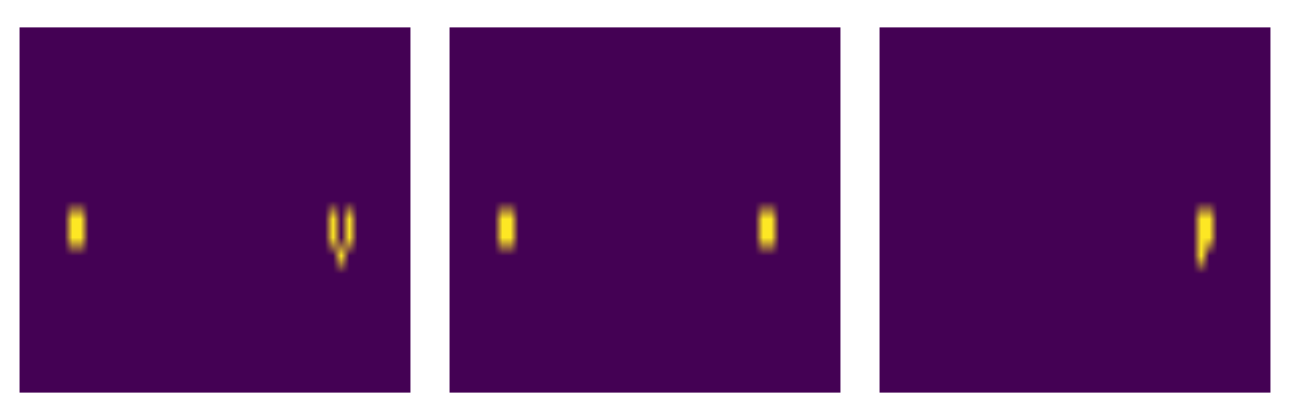

Divergences a l'etape 1 : 5 cellules, aux positions : [(7, 47), (8, 47), (8, 48), (9, 47), (9, 48)]


La carte de divergence est entierement autour de la frontiere de B : deux cellules du bloc


predites vivantes (valeur transportee = bloc stable) mais mortes de surpopulation,


et trois cellules que la valeur isolee ne peut pas voir (le temoin qui survit avec


2 voisins, deux naissances de l'autre cote de la frontiere).


In [9]:
#r "nuget:ScottPlot, 5.0.55"

// Étape 1 du recollement cassé sur le corpus : la collision A/B rendue visible.
var grilleFigure = corpus_frontiere();
var veriteFigure = pas_suivant(grilleFigure);
var memoFigure = new Dictionary<string, bool[,]>();
var statsFigure = nouvelles_stats();
var predFigure = predire_recolle(grilleFigure, 4, 0, memoFigure, statsFigure);
var positionsFigure = new List<(int ligne, int colonne)>();
var cartesFigure = new[] { new double[20, 48], new double[20, 48], new double[20, 48] };
for (int i = 0; i < 64; i++)
    for (int j = 0; j < 64; j++)
    {
        bool divergence = predFigure[i, j] != veriteFigure[i, j];
        if (divergence) positionsFigure.Add((i, j));
        if (i < 20 && j >= 8 && j < 56)
        {
            // ScottPlot place la première ligne en bas : retourner l'axe vertical.
            cartesFigure[0][19 - i, j - 8] = veriteFigure[i, j] ? 1 : 0;
            cartesFigure[1][19 - i, j - 8] = predFigure[i, j] ? 1 : 0;
            cartesFigure[2][19 - i, j - 8] = divergence ? 1 : 0;
        }
    }

string[] titresFigure = { "Verite terrain a t+1", "Prediction du recollement casse", "Carte de divergence (pred != verite)" };
var svgFigure = new System.Text.StringBuilder();
svgFigure.Append("<svg xmlns='http://www.w3.org/2000/svg' xmlns:xlink='http://www.w3.org/1999/xlink' width='1300' height='420' viewBox='0 0 1300 420'>");
svgFigure.Append("<rect width='1300' height='420' fill='white'/>");
for (int panneau = 0; panneau < 3; panneau++)
{
    var graphique = new ScottPlot.Plot();
    graphique.Add.Heatmap(cartesFigure[panneau]);
    graphique.Title(titresFigure[panneau]);
    graphique.Axes.Frameless();
    graphique.HideGrid();
    string svgPanneau = graphique.GetSvgXml(430, 420);
    string donnees = Convert.ToBase64String(System.Text.Encoding.UTF8.GetBytes(svgPanneau));
    svgFigure.Append($"<image x='{panneau * 430}' y='0' width='430' height='420' xlink:href='data:image/svg+xml;base64,{donnees}'/>");
}
svgFigure.Append("</svg>");
Microsoft.DotNet.Interactive.Formatting.Formatter.Register<string>((valeur, writer) => writer.Write(valeur), "image/svg+xml");
Microsoft.DotNet.Interactive.Kernel.display(svgFigure.ToString(), "image/svg+xml");
Console.WriteLine($"Divergences a l'etape 1 : {positionsFigure.Count} cellules, aux positions : [" + string.Join(", ", positionsFigure.Select(p => $"({p.ligne}, {p.colonne})")) + "]");
Console.WriteLine("La carte de divergence est entierement autour de la frontiere de B : deux cellules du bloc");
Console.WriteLine("predites vivantes (valeur transportee = bloc stable) mais mortes de surpopulation,");
Console.WriteLine("et trois cellules que la valeur isolee ne peut pas voir (le temoin qui survit avec");
Console.WriteLine("2 voisins, deux naissances de l'autre cote de la frontiere).");

### Lecture — la collision, vue de pres

Les deux blocs a gauche (macrocells A et B) ont le meme interieur ; les cinq cellules divergentes sont **toutes** dans la zone de frontiere de B, aucune ailleurs : les deux cellules du bloc que la valeur transportee annoncait vivantes (mortes de surpopulation en verite), le temoin que la valeur isolee laissait mourir (il survit), et deux naissances que l'interieur seul ne pouvait pas produire. La divergence est **localisee exactement la ou le recouvrement etait incoherent** — pas diffuse, pas globale : le defaut de compatibilite a une adresse.

## Vérifiez votre compréhension

### Exercice 1 — la cle canonique recursive du quadtree

La cle de ce notebook est plate (les octets du patch). Hashlife utilise une cle **recursive** : un noeud de niveau k est identifie par le tuple de ses quatre fils. Ecrire `forme_canonique` pour un carre de cote `2^k`.

**Indices** :
- `// Etape 1` : cas de base — un carre 1×1 est une feuille, sa forme est le booléen lui-meme.
- `// Etape 2` : un carre de cote `q` se decoupe en quatre quadrants de cote `q / 2`.
- `// Etape 3` : la forme canonique est le tuple `(NO, NE, SO, SE)` des formes canoniques des quatre fils — deux quadtrees de la meme forme donnent le meme tuple.

In [10]:
// Exercice 1 — forme canonique recursive
object forme_canonique(bool[,] grille)
{
    // Etape 1 : cas de base 1x1
    // TODO etudiant : traiter la feuille.
    // Etape 2 : decoupage en 4 quadrants egaux
    // TODO etudiant : extraire les quatre quadrants.
    // Etape 3 : tuple recursif
    // TODO etudiant : assembler les formes des quatre fils.
    return null; // TODO etudiant
}
Console.WriteLine("Exercice a completer : forme_canonique (quadtree recursif)");

Exercice a completer : forme_canonique (quadtree recursif)


### Exercice 2 — votre propre soupe, votre propre sensibilite

Reproduire l'experience du §6 sur une soupe que vous choisissez (grille 32×32, densite 0,3, `T=10`, `m=4`) et comparer les divergences pour marge 0 et marge 1.

**Indices** :
- `// Indice` : `soupe(32, 32, 0.3, seed)` construit la soupe ; `experience(g0, 4, marge, 10)` rend `(stats, profit)`.
- `// Etape 1` : lancer `experience` avec `marge=0` puis `marge=1` sur la meme soupe.
- `// Etape 2` : rapporter les deux `stats["divergences"]` — attendu : strictement positif contre zero.

In [11]:
// Exercice 2 — sensibilite d'une soupe
// TODO etudiant : construire votre soupe 32x32 (densite 0.3, seed au choix)
// ma_soupe = ...
// Etape 1 : lancer experience(ma_soupe, 4, 0, 10) puis experience(ma_soupe, 4, 1, 10)
// Etape 2 : rapporter les divergences
int? div_marge0 = null; // TODO etudiant : stats["divergences"] pour marge=0
int? div_marge1 = null; // TODO etudiant : stats["divergences"] pour marge=1
Console.WriteLine("Exercice a completer : sensibilite de la marge sur votre propre soupe");

Exercice a completer : sensibilite de la marge sur votre propre soupe


### Exercice 3 — le bookmaker systematique

Mesurer le profit total du bookmaker sur **dix soupes** (seeds 0 a 9, grille 64×64, densite 0,35, `T=10`, `m=4`), contre un agent fie au recollement casse, puis contre un agent fie au recollement sain.

**Indices** :
- `// Indice` : `session_bookmaker(g0, 4, marge, 10)` rend le profit total.
- `// Etape 1` : boucler sur les seeds, sommer les profits pour `marge=0`.
- `// Etape 2` : recommencer pour `marge=1` — attendu : total strict contre zero.

In [12]:
// Exercice 3 — le bookmaker systematique
// Etape 1 : profit total du bookmaker sur les seeds 0..9, recollement casse
int? profit_total_casse = null; // TODO etudiant : somme des session_bookmaker(..., marge=0, T=10)
// Etape 2 : idem, recollement sain
int? profit_total_sain = null; // TODO etudiant : somme des session_bookmaker(..., marge=1, T=10)
Console.WriteLine("Exercice a completer : le bookmaker systematique sur dix soupes");

Exercice a completer : le bookmaker systematique sur dix soupes


## À retenir

| Experience | Recollement sain (marge 1) | Recollement casse (marge 0) |
|---|---|---|
| Corpus frontiere (T=16) | 0 divergence, 0 transport faux | divergences des l'etape 1, temoin rentable |
| Soupe seed 7 (T=30) | 0 divergence, tous les transports exacts | majorite des transports faux, temoin rentable |
| Variante -b (marge 0/1/2) | 0 divergence des la marge 1 | marge 2 n'ajoute rien : la marche d'escalier est au rayon du voisinage |
| Variante -c (r=1 vs r=2) | marge saine = rayon causal : sur des 1 pour les deux regles r=1, des 2 pour la regle r=2 | la marge 1 « heritee de Life » diverge sur la regle r=2 (3 soupes) : le temoin encaisse |

Ce que le strand 15b-15i n'avait pas — et que ce notebook pose :

- un **recouvrement impose par le substrat** (quadtree aligne sur `2^k`), pas choisi pour faire apparaitre un resultat ;
- des **fibres et des transports reels** (la memo reutilise des valeurs entre occurrences distantes), et une **compatibilite verifiee empiriquement** (zero transport faux, zero divergence, contre verite terrain) ;
- la **Loi I repondue dans les deux sens** : le defaut de compatibilite injecte se convertit en temoin qui paie (Dutch Book sur la population annoncee), et le recollement sain est inexploitable — c'est la version instance par instance de `hashlife_correct` (ICT-Life §5) ;
- la **dette du §2 rendue observable** : le choix des bords n'est pas une convention, c'est un parametre calibre par la portee locale de la dynamique, et la table de sensibilite le mesure.

**Limites honnetes.** Nous memoizons **un pas** (marge 1, rayon du voisinage) — pas les sauts temporels `2^k` du Hashlife complet de Gosper ; la grille est 64×64 a bord mort ; les corpus sont petits et le corpus frontiere est construit pour exhiber la collision (la soupe montre que le phenomene existe aussi sans le vouloir). Le volet 2 de #12206 (banc de recollement de lectures heterogenes) reste a brancher sur un corpus reel, et le volet 3 (`Descent.lean`) a ouvrir.

## Références et provenance

- Chantier de recollement : issue #12206; constat antérieur de trivialité : issue #7744; série ICT : issue #4588.
- R. W. Gosper, *Hash Life*, mémo, 1984.
- Prérequis et navigation : [ICT-Life-SubstratCertifie-Python](../ICT-Life-SubstratCertifie-Python.ipynb), [ICT-31-ContrasteTroisSubstrats-Python](../ICT-31-ContrasteTroisSubstrats-Python.ipynb), `conway_lean/Conway/Life/HashlifeCorrectness.lean`.
- **Jumeau Python** → [ICT-15k-RecollementMacroCells-Python](ICT-15k-RecollementMacroCells-Python.ipynb) — le carnet d'origine, en Python.

## Pour aller plus loin

- Le substrat certifié et le Hashlife formel : [ICT-Life — SubstratCertifié](../ICT-Life-SubstratCertifie-Python.ipynb), et `conway_lean/Conway/Life/HashlifeCorrectness.lean` pour la version preuve.
- Le contraste trois substrats : [ICT-31](../ICT-31-ContrasteTroisSubstrats-Python.ipynb).
- Le volet 2 de #12206 (banc de recollement de lectures hétérogènes) et le volet 3 (`Descent.lean`) restent à brancher — voir la section Limites honnêtes ci-dessus.
- Revenir au [cadrage de la série](../ICT-0-Framing.md).